# Polyp Segmentation — Kvasir-SEG
**Model:** ResNet50 + MSFF + CBAM | **Loss:** Dice+BCE | **Split:** 70/15/15

**Changes v2:**
- Early Stopping patience → 5
- Full metric logging: Loss, Dice, IoU, Acc, LR per epoch
- Baseline comparison (ResNet50 backbone only)
- Ablation study (No MSFF / No CBAM / Conv only / No pretrained)
- Single-image inference utility


In [2]:
import torch
print("PyTorch :", torch.__version__)
print("CUDA    :", torch.cuda.is_available())
if torch.cuda.is_available(): print("GPU     :", torch.cuda.get_device_name(0))
!pip install -q albumentations==1.3.1
print("Libraries ready!")


PyTorch : 2.11.0+cu128
CUDA    : True
GPU     : Tesla T4
Libraries ready!


## Step 1: Mount Drive & Load Dataset

In [3]:
from google.colab import drive
drive.mount("/content/drive")
import os, subprocess
zip_path = "/content/drive/MyDrive/archive.zip"
if not os.path.exists("/content/kvasir-seg"):
    subprocess.run(["unzip", "-q", zip_path, "-d", "/content/"], check=True)
    print("Extracted!")
else:
    print("Already extracted!")
DATA_DIR = "/content/kvasir-seg"
print("Images:", len(os.listdir(os.path.join(DATA_DIR, "images"))))
print("Masks :", len(os.listdir(os.path.join(DATA_DIR, "masks"))))


Mounted at /content/drive
Extracted!
Images: 1000
Masks : 1000


## Step 2: Imports & Config

In [4]:
import os, csv, time, random
import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.utils.data import Dataset, DataLoader
import torchvision.models as models
import albumentations as A
from albumentations.pytorch import ToTensorV2

CFG = {
    "DATA_DIR"    : "/content/kvasir-seg",
    "IMG_SIZE"    : 352,
    "BATCH_SIZE"  : 8,
    "EPOCHS"      : 100,
    "LR"          : 1e-4,
    "WEIGHT_DECAY": 1e-4,
    "PATIENCE"    : 5,
    "BACKBONE"    : "resnet50",
    "SEED"        : 42,
    "NUM_WORKERS" : 2,
    "OUTPUT_DIR"  : "/content/outputs"
}
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
os.makedirs(CFG["OUTPUT_DIR"], exist_ok=True)
random.seed(CFG["SEED"]); np.random.seed(CFG["SEED"]); torch.manual_seed(CFG["SEED"])
if torch.cuda.is_available(): torch.cuda.manual_seed_all(CFG["SEED"])
print("Device  :", DEVICE)
print("DATA_DIR:", CFG["DATA_DIR"])
print("PATIENCE:", CFG["PATIENCE"], "(Early Stopping)")


Device  : cuda
DATA_DIR: /content/kvasir-seg
PATIENCE: 5 (Early Stopping)


## Step 3: Dataset & Augmentation (70/15/15)

Train=700  Val=150  Test=150


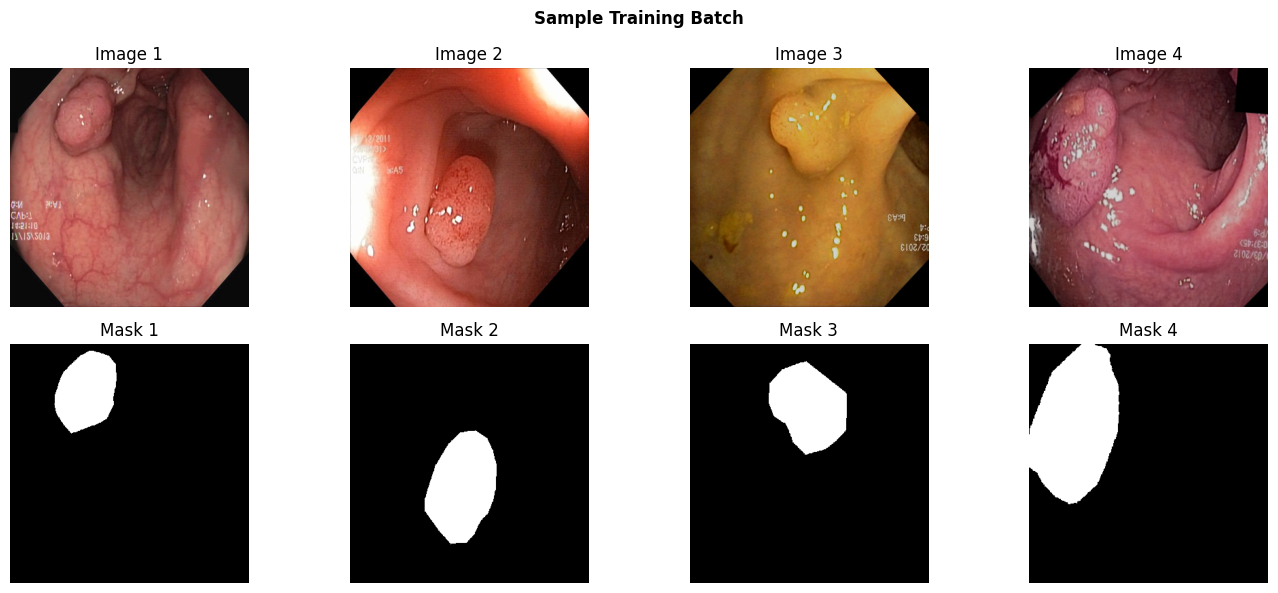

In [5]:
def get_train_transforms(sz):
    return A.Compose([
        A.Resize(sz, sz), A.HorizontalFlip(p=0.5), A.VerticalFlip(p=0.5),
        A.RandomRotate90(p=0.5),
        A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1, rotate_limit=15, p=0.5),
        A.OneOf([A.ElasticTransform(p=0.5), A.GridDistortion(p=0.5), A.OpticalDistortion(p=0.5)], p=0.3),
        A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1, p=0.5),
        A.GaussNoise(var_limit=(10.0, 50.0), p=0.2),
        A.Normalize(mean=(0.485,0.456,0.406), std=(0.229,0.224,0.225)), ToTensorV2()])

def get_val_transforms(sz):
    return A.Compose([
        A.Resize(sz, sz),
        A.Normalize(mean=(0.485,0.456,0.406), std=(0.229,0.224,0.225)), ToTensorV2()])

class KvasirSEGDataset(Dataset):
    def __init__(self, imgs, masks, tfm=None):
        self.imgs=imgs; self.masks=masks; self.tfm=tfm
    def __len__(self): return len(self.imgs)
    def __getitem__(self, i):
        img = np.array(Image.open(self.imgs[i]).convert("RGB"))
        msk = np.array(Image.open(self.masks[i]).convert("L"))
        msk = (msk > 127).astype(np.float32)
        if self.tfm:
            a=self.tfm(image=img,mask=msk); img=a["image"]; msk=a["mask"].unsqueeze(0)
        return img, msk

def build_dataloaders(cfg):
    img_dir  = os.path.join(cfg["DATA_DIR"], "images")
    mask_dir = os.path.join(cfg["DATA_DIR"], "masks")
    fn = sorted(os.listdir(img_dir))
    imgs  = [os.path.join(img_dir,  f) for f in fn]
    masks = [os.path.join(mask_dir, f) for f in fn]
    idx = list(range(len(fn))); random.shuffle(idx)
    imgs=[imgs[i] for i in idx]; masks=[masks[i] for i in idx]
    n=len(fn); nt=int(0.70*n); nv=int(0.15*n); sz=cfg["IMG_SIZE"]
    trd=KvasirSEGDataset(imgs[:nt],      masks[:nt],      get_train_transforms(sz))
    vld=KvasirSEGDataset(imgs[nt:nt+nv], masks[nt:nt+nv], get_val_transforms(sz))
    ted=KvasirSEGDataset(imgs[nt+nv:],   masks[nt+nv:],   get_val_transforms(sz))
    print("Train={}  Val={}  Test={}".format(len(trd),len(vld),len(ted)))
    kw=dict(batch_size=cfg["BATCH_SIZE"],num_workers=cfg["NUM_WORKERS"],pin_memory=True)
    return (DataLoader(trd,shuffle=True,**kw), DataLoader(vld,shuffle=False,**kw), DataLoader(ted,shuffle=False,**kw))

train_loader, val_loader, test_loader = build_dataloaders(CFG)

MEAN=np.array([0.485,0.456,0.406]); STD=np.array([0.229,0.224,0.225])
imgs_s,msks_s=next(iter(train_loader))
fig,axes=plt.subplots(2,4,figsize=(14,6))
for i in range(4):
    img=np.clip(imgs_s[i].permute(1,2,0).numpy()*STD+MEAN,0,1)
    axes[0,i].imshow(img); axes[0,i].set_title("Image {}".format(i+1)); axes[0,i].axis("off")
    axes[1,i].imshow(msks_s[i,0],cmap="gray"); axes[1,i].set_title("Mask {}".format(i+1)); axes[1,i].axis("off")
plt.suptitle("Sample Training Batch",fontweight="bold"); plt.tight_layout(); plt.show()


## Step 4: Model Architecture
### 4A: Shared building blocks (CBAM, MSFF, DecoderBlock)

In [6]:
# ─── Attention modules ─────────────────────────────────────────
class ChannelAttention(nn.Module):
    def __init__(self, in_c, r=16):
        super().__init__()
        mid = max(in_c // r, 1)
        self.avg = nn.AdaptiveAvgPool2d(1)
        self.max = nn.AdaptiveMaxPool2d(1)
        self.fc  = nn.Sequential(
            nn.Conv2d(in_c, mid, 1, bias=False), nn.ReLU(True),
            nn.Conv2d(mid, in_c, 1, bias=False))
        self.sig = nn.Sigmoid()
    def forward(self, x):
        return x * self.sig(self.fc(self.avg(x)) + self.fc(self.max(x)))

class SpatialAttention(nn.Module):
    def __init__(self, k=7):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, k, padding=k//2, bias=False)
        self.sig  = nn.Sigmoid()
    def forward(self, x):
        a = x.mean(1, keepdim=True)
        m, _ = x.max(1, keepdim=True)
        return x * self.sig(self.conv(torch.cat([a, m], 1)))

class CBAM(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.ca = ChannelAttention(c)
        self.sa = SpatialAttention()
    def forward(self, x): return self.sa(self.ca(x))

def cbr(i, o, k=3, p=1):
    return nn.Sequential(
        nn.Conv2d(i, o, k, padding=p, bias=False),
        nn.BatchNorm2d(o), nn.ReLU(True))

class DecoderBlock(nn.Module):
    def __init__(self, in_c, sk_c, out_c, use_cbam=True):
        super().__init__()
        self.conv = nn.Sequential(cbr(in_c + sk_c, out_c), cbr(out_c, out_c))
        self.attn = CBAM(out_c) if use_cbam else nn.Identity()
        # Residual connection: 1x1 conv to match channels
        self.res  = nn.Conv2d(in_c + sk_c, out_c, 1, bias=False) if (in_c + sk_c) != out_c else nn.Identity()
    def forward(self, x, skip=None):
        x = F.interpolate(x, scale_factor=2, mode="bilinear", align_corners=False)
        if skip is not None:
            if x.shape[2:] != skip.shape[2:]:
                x = F.interpolate(x, size=skip.shape[2:], mode="bilinear", align_corners=False)
            x = torch.cat([x, skip], 1)
        out = self.conv(x)
        out = out + self.res(x)  # residual connection
        return self.attn(out)

class MSFF(nn.Module):
    def __init__(self, chs, out_c=256):
        super().__init__()
        self.projs = nn.ModuleList([
            nn.Sequential(nn.Conv2d(c, out_c, 1, bias=False),
                          nn.BatchNorm2d(out_c), nn.ReLU(True)) for c in chs])
        self.fuse = cbr(out_c, out_c)
    def forward(self, feats, tgt):
        out = None
        for p, f in zip(self.projs, feats):
            ff  = F.interpolate(p(f), size=tgt, mode="bilinear", align_corners=False)
            out = ff if out is None else out + ff
        return self.fuse(out)

print("Building blocks ready!")


Building blocks ready!


### 4B: Full Model (MSFF + CBAM + Residual) — Main model

In [7]:
class PolypSegNet(nn.Module):
    """
    Full model: ResNet50 encoder + MSFF neck + CBAM decoder + residual connections.
    Ablation flags:
      use_msff  – set False to replace MSFF with a plain 1x1 projection of enc4
      use_cbam  – set False to remove CBAM from all decoder blocks
      pretrained – set False to train backbone from scratch
    """
    def __init__(self, backbone="resnet50", pretrained=True, use_msff=True, use_cbam=True):
        super().__init__()
        b = models.resnet50(
            weights=models.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None)
        self.enc0 = nn.Sequential(b.conv1, b.bn1, b.relu, b.maxpool)
        self.enc1 = b.layer1
        self.enc2 = b.layer2
        self.enc3 = b.layer3
        self.enc4 = b.layer4
        ec = [64, 256, 512, 1024, 2048]
        self.use_msff = use_msff
        if use_msff:
            self.msff = MSFF([ec[2], ec[3], ec[4]], 256)
        else:
            # No MSFF: plain conv from enc4 only
            self.msff = nn.Sequential(
                nn.Conv2d(ec[4], 256, 1, bias=False), nn.BatchNorm2d(256), nn.ReLU(True))
        self.dec4 = DecoderBlock(256, ec[1], 128, use_cbam=use_cbam)
        self.dec3 = DecoderBlock(128, ec[0],  64, use_cbam=use_cbam)
        self.dec2 = DecoderBlock(64,  0,       32, use_cbam=use_cbam)
        self.dec1 = DecoderBlock(32,  0,       16, use_cbam=use_cbam)
        self.head = nn.Conv2d(16, 1, 1)

    def forward(self, x):
        H, W = x.shape[2:]
        e0 = self.enc0(x)
        e1 = self.enc1(e0)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        e4 = self.enc4(e3)
        if self.use_msff:
            neck = self.msff([e2, e3, e4], (e2.shape[2], e2.shape[3]))
        else:
            neck = F.interpolate(self.msff(e4), size=(e2.shape[2], e2.shape[3]),
                                 mode="bilinear", align_corners=False)
        d = self.dec4(neck, e1)
        d = self.dec3(d,    e0)
        d = self.dec2(d,    None)
        d = self.dec1(d,    None)
        d = F.interpolate(d, (H, W), mode="bilinear", align_corners=False)
        return torch.sigmoid(self.head(d))

# Build the MAIN model
model = PolypSegNet(backbone=CFG["BACKBONE"], pretrained=True,
                    use_msff=True, use_cbam=True).to(DEVICE)
n_p = sum(p.numel() for p in model.parameters()) / 1e6
print("Backbone : {}".format(CFG["BACKBONE"]))
print("Params   : {:.2f}M".format(n_p))
with torch.no_grad():
    _out = model(torch.randn(1,3,352,352).to(DEVICE))
print("Output   : {}  OK!".format(tuple(_out.shape)))


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 130MB/s]


Backbone : resnet50
Params   : 26.02M
Output   : (1, 1, 352, 352)  OK!


## Step 5: Loss & Metrics

In [8]:
class DiceLoss(nn.Module):
    def __init__(self, smooth=1.0): super().__init__(); self.s=smooth
    def forward(self, p, t):
        p=p.contiguous().view(-1); t=t.contiguous().view(-1)
        inter=(p*t).sum()
        return 1-(2*inter+self.s)/(p.sum()+t.sum()+self.s)

class DiceBCELoss(nn.Module):
    def __init__(self,alpha=0.5):
        super().__init__(); self.alpha=alpha; self.dice=DiceLoss(); self.bce=nn.BCELoss()
    def forward(self,p,t): return self.alpha*self.dice(p,t)+(1-self.alpha)*self.bce(p,t)

class MetricMeter:
    def __init__(self,thr=0.5): self.thr=thr; self.reset()
    def reset(self):
        self.s={"dice":0.,"iou":0.,"prec":0.,"rec":0.,"f2":0.,"mae":0.,"acc":0.}; self.n=0
    def update(self,pred,tgt):
        pred=pred.detach().cpu(); tgt=tgt.detach().cpu(); pb=(pred>self.thr).float()
        for b in range(pred.shape[0]):
            p=pb[b].view(-1); t=tgt[b].view(-1); sm=1e-6
            TP=(p*t).sum(); FP=(p*(1-t)).sum(); FN=((1-p)*t).sum(); TN=((1-p)*(1-t)).sum()
            self.s["dice"]+=((2*TP+sm)/(2*TP+FP+FN+sm)).item()
            self.s["iou"] +=((TP+sm)/(TP+FP+FN+sm)).item()
            self.s["prec"]+=((TP+sm)/(TP+FP+sm)).item()
            self.s["rec"] +=((TP+sm)/(TP+FN+sm)).item()
            self.s["f2"]  +=((5*TP+sm)/(5*TP+4*FN+FP+sm)).item()
            self.s["mae"] +=(pred[b]-tgt[b]).abs().mean().item()
            self.s["acc"] +=((TP+TN+sm)/(TP+TN+FP+FN+sm)).item()  # pixel accuracy
            self.n+=1
    def compute(self): return {k:v/self.n for k,v in self.s.items()} if self.n else self.s

print("Loss & Metrics ready! (includes Accuracy)")


Loss & Metrics ready! (includes Accuracy)


## Step 6: Training Loop with Full Logging

In [9]:
class EarlyStopping:
    def __init__(self, patience=5, path="best_model.pth", delta=1e-4):
        self.patience=patience; self.path=path; self.delta=delta
        self.best=None; self.counter=0; self.triggered=False
    def __call__(self, score, model):
        if self.best is None or score > self.best + self.delta:
            self.best=score; self.counter=0
            torch.save(model.state_dict(), self.path)
            print("  ✔ Best model saved  (val_dice={:.4f})".format(score))
        else:
            self.counter += 1
            print("  EarlyStopping: {}/{}".format(self.counter, self.patience))
            if self.counter >= self.patience: self.triggered = True

criterion = DiceBCELoss(alpha=0.5)
optimizer = optim.AdamW(model.parameters(), lr=CFG["LR"], weight_decay=CFG["WEIGHT_DECAY"])
scheduler = CosineAnnealingLR(optimizer, T_max=CFG["EPOCHS"], eta_min=1e-6)
ckpt_path = os.path.join(CFG["OUTPUT_DIR"], "best_model.pth")
stopper   = EarlyStopping(patience=CFG["PATIENCE"], path=ckpt_path)

def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total = 0.; meter = MetricMeter()
    ctx = torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for imgs, msks in loader:
            imgs = imgs.to(DEVICE, non_blocking=True)
            msks = msks.to(DEVICE, non_blocking=True)
            if train: optimizer.zero_grad()
            preds = model(imgs)
            loss  = criterion(preds, msks)
            if train:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
            total += loss.item() * imgs.size(0)
            meter.update(preds, msks)
    m = meter.compute()
    m["loss"] = total / len(loader.dataset)
    return m

# Full history — all metrics logged per epoch (epoch 1 to 100)
history = {
    "epoch":      [],
    "lr":         [],
    "train_loss": [], "train_dice": [], "train_iou":  [], "train_acc":  [],
    "val_loss":   [], "val_dice":   [], "val_iou":    [], "val_acc":    []
}

print("="*65)
print(" TRAINING START  (Early Stopping patience={})".format(CFG["PATIENCE"]))
print("="*65)

for epoch in range(1, CFG["EPOCHS"]+1):
    t0 = time.time()
    tr = run_epoch(train_loader, train=True)
    vl = run_epoch(val_loader,   train=False)
    scheduler.step()
    lr = scheduler.get_last_lr()[0]

    history["epoch"].append(epoch)
    history["lr"].append(lr)
    history["train_loss"].append(tr["loss"])
    history["train_dice"].append(tr["dice"])
    history["train_iou"].append(tr["iou"])
    history["train_acc"].append(tr["acc"])
    history["val_loss"].append(vl["loss"])
    history["val_dice"].append(vl["dice"])
    history["val_iou"].append(vl["iou"])
    history["val_acc"].append(vl["acc"])

    print("Epoch [{:03d}/{}] {:.0f}s  lr={:.2e}".format(epoch, CFG["EPOCHS"], time.time()-t0, lr))
    print("  Train  loss={:.4f}  dice={:.4f}  iou={:.4f}  acc={:.4f}".format(
          tr["loss"], tr["dice"], tr["iou"], tr["acc"]))
    print("  Val    loss={:.4f}  dice={:.4f}  iou={:.4f}  acc={:.4f}".format(
          vl["loss"], vl["dice"], vl["iou"], vl["acc"]))
    stopper(vl["dice"], model)
    if stopper.triggered:
        print("EarlyStopping triggered! Best val Dice={:.4f}".format(stopper.best))
        break

# Save full history to CSV
hist_csv = os.path.join(CFG["OUTPUT_DIR"], "training_history.csv")
with open(hist_csv, "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(history.keys())
    w.writerows(zip(*history.values()))
print("History saved:", hist_csv)


 TRAINING START  (Early Stopping patience=5)
Epoch [001/100] 43s  lr=1.00e-04
  Train  loss=0.5703  dice=0.6052  iou=0.4898  acc=0.9050
  Val    loss=0.2762  dice=0.7937  iou=0.6910  acc=0.9358
  ✔ Best model saved  (val_dice=0.7937)
Epoch [002/100] 44s  lr=9.99e-05
  Train  loss=0.2447  dice=0.7724  iou=0.6681  acc=0.9392
  Val    loss=0.1801  dice=0.8406  iou=0.7513  acc=0.9475
  ✔ Best model saved  (val_dice=0.8406)
Epoch [003/100] 45s  lr=9.98e-05
  Train  loss=0.1799  dice=0.8188  iou=0.7305  acc=0.9502
  Val    loss=0.1510  dice=0.8667  iou=0.7856  acc=0.9556
  ✔ Best model saved  (val_dice=0.8667)
Epoch [004/100] 46s  lr=9.96e-05
  Train  loss=0.1598  dice=0.8385  iou=0.7543  acc=0.9560
  Val    loss=0.1584  dice=0.8598  iou=0.7815  acc=0.9526
  EarlyStopping: 1/5
Epoch [005/100] 46s  lr=9.94e-05
  Train  loss=0.1405  dice=0.8530  iou=0.7739  acc=0.9607
  Val    loss=0.1508  dice=0.8664  iou=0.7887  acc=0.9539
  EarlyStopping: 2/5
Epoch [006/100] 46s  lr=9.91e-05
  Train  loss=0

## Step 7: Training Curves (Loss / Dice / IoU / Acc / LR)

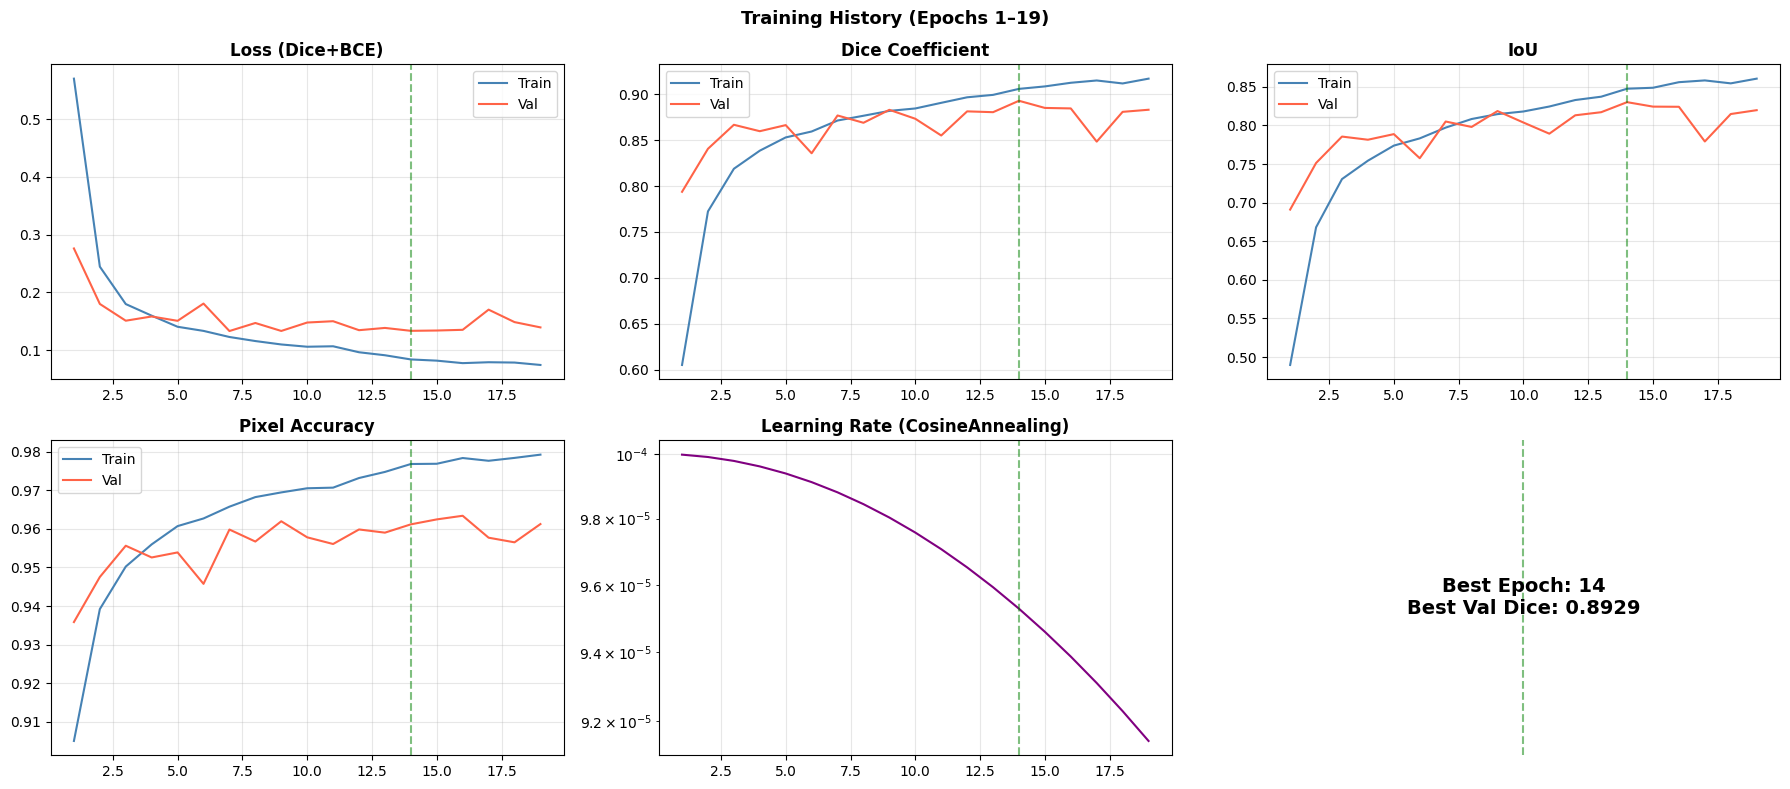

Saved: /content/outputs/training_curves.png


In [10]:
e = history["epoch"]
fig, axes = plt.subplots(2, 3, figsize=(18, 8))

def plot_metric(ax, key, title, logy=False):
    ax.plot(e, history["train_"+key], label="Train", color="steelblue")
    ax.plot(e, history["val_"+key],   label="Val",   color="tomato")
    ax.set_title(title, fontweight="bold"); ax.legend(); ax.grid(alpha=0.3)
    if logy: ax.set_yscale("log")

plot_metric(axes[0,0], "loss", "Loss (Dice+BCE)")
plot_metric(axes[0,1], "dice", "Dice Coefficient")
plot_metric(axes[0,2], "iou",  "IoU")
plot_metric(axes[1,0], "acc",  "Pixel Accuracy")

axes[1,1].plot(e, history["lr"], color="purple")
axes[1,1].set_title("Learning Rate (CosineAnnealing)", fontweight="bold")
axes[1,1].set_yscale("log"); axes[1,1].grid(alpha=0.3)

# Best epoch marker
best_ep = history["val_dice"].index(max(history["val_dice"]))
for ax in axes.flat:
    ax.axvline(x=e[best_ep], color="green", linestyle="--", alpha=0.5, label="Best")
axes[1,2].text(0.5,0.5, "Best Epoch: {}\nBest Val Dice: {:.4f}".format(
    e[best_ep], max(history["val_dice"])), ha="center", va="center",
    fontsize=14, fontweight="bold", transform=axes[1,2].transAxes)
axes[1,2].axis("off")

plt.suptitle("Training History (Epochs 1–{})".format(e[-1]), fontsize=13, fontweight="bold")
plt.tight_layout()
out_c = os.path.join(CFG["OUTPUT_DIR"], "training_curves.png")
plt.savefig(out_c, dpi=150, bbox_inches="tight"); plt.show()
print("Saved:", out_c)


## Step 8: Test Evaluation

In [11]:
model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
tm = run_epoch(test_loader, train=False)
print("="*45)
print(" TEST RESULTS (Best Weights)")
print("="*45)
for k,v in tm.items(): print("  {:12s}: {:.4f}".format(k,v))
print("="*45)
rp=os.path.join(CFG["OUTPUT_DIR"],"test_results.csv")
with open(rp,"w",newline="") as f:
    w=csv.writer(f); w.writerow(["Metric","Value"])
    for k,v in tm.items(): w.writerow([k,"{:.6f}".format(v)])
print("Saved:",rp)


 TEST RESULTS (Best Weights)
  dice        : 0.9039
  iou         : 0.8437
  prec        : 0.9080
  rec         : 0.9222
  f2          : 0.9111
  mae         : 0.0347
  acc         : 0.9695
  loss        : 0.1049
Saved: /content/outputs/test_results.csv


## Step 9: Ablation Study
Trains 4 ablation variants and compares against the full model.

| Variant | MSFF | CBAM | Pretrained | Notes |
|---------|------|------|------------|-------|
| Baseline (ResNet50 only) | ✗ | ✗ | ✓ | Plain decoder |
| No MSFF | ✗ | ✓ | ✓ | Single-scale neck |
| No CBAM | ✓ | ✗ | ✓ | No attention |
| No Pretrained | ✓ | ✓ | ✗ | Train from scratch |
| **Full Model** | ✓ | ✓ | ✓ | **Ours** |


In [12]:
def train_ablation(name, use_msff, use_cbam, pretrained, epochs=20):
    """Quick ablation run (reduced epochs for comparison speed)."""
    print("\n" + "="*55)
    print(" ABLATION: {}".format(name))
    print("="*55)
    m = PolypSegNet(backbone="resnet50",
                    pretrained=pretrained,
                    use_msff=use_msff,
                    use_cbam=use_cbam).to(DEVICE)
    n_p = sum(p.numel() for p in m.parameters()) / 1e6
    print("  Params: {:.2f}M | MSFF={} CBAM={} Pretrained={}".format(
          n_p, use_msff, use_cbam, pretrained))
    opt = optim.AdamW(m.parameters(), lr=CFG["LR"], weight_decay=CFG["WEIGHT_DECAY"])
    sch = CosineAnnealingLR(opt, T_max=epochs, eta_min=1e-6)
    crit = DiceBCELoss(alpha=0.5)
    ckpt = os.path.join(CFG["OUTPUT_DIR"], "ablation_{}.pth".format(name.replace(" ","_")))
    stopper_abl = EarlyStopping(patience=CFG["PATIENCE"], path=ckpt)
    best_dice = 0.
    for ep in range(1, epochs+1):
        m.train()
        for imgs, msks in train_loader:
            imgs=imgs.to(DEVICE); msks=msks.to(DEVICE)
            opt.zero_grad()
            loss = crit(m(imgs), msks)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0)
            opt.step()
        sch.step()
        m.eval()
        meter = MetricMeter()
        with torch.no_grad():
            for imgs, msks in val_loader:
                meter.update(m(imgs.to(DEVICE)), msks.to(DEVICE))
        vl = meter.compute()
        print("  Ep {:02d}  val_dice={:.4f}  val_iou={:.4f}".format(ep, vl["dice"], vl["iou"]))
        stopper_abl(vl["dice"], m)
        if stopper_abl.triggered:
            print("  EarlyStopping!"); break
    # Load best weights and evaluate on test set
    m.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    m.eval()
    meter = MetricMeter()
    with torch.no_grad():
        for imgs, msks in test_loader:
            meter.update(m(imgs.to(DEVICE)), msks.to(DEVICE))
    res = meter.compute()
    print("  TEST → dice={:.4f}  iou={:.4f}  acc={:.4f}".format(
          res["dice"], res["iou"], res["acc"]))
    return res

ablation_results = {}

# ① Baseline: ResNet50 only, no MSFF, no CBAM
ablation_results["Baseline"]       = train_ablation("Baseline",        use_msff=False, use_cbam=False, pretrained=True)
# ② No MSFF
ablation_results["No MSFF"]        = train_ablation("No MSFF",         use_msff=False, use_cbam=True,  pretrained=True)
# ③ No CBAM
ablation_results["No CBAM"]        = train_ablation("No CBAM",         use_msff=True,  use_cbam=False, pretrained=True)
# ④ No Pretrained
ablation_results["No Pretrained"]  = train_ablation("No Pretrained",   use_msff=True,  use_cbam=True,  pretrained=False)
# ⑤ Full model test result (already computed above)
ablation_results["Full Model"]     = tm

print("\n" + "="*65)
print(" ABLATION SUMMARY")
print("{:<18s} {:>8s} {:>8s} {:>8s}".format("Variant","Dice","IoU","Acc"))
print("-"*44)
for name, res in ablation_results.items():
    print("{:<18s} {:>8.4f} {:>8.4f} {:>8.4f}".format(name, res["dice"], res["iou"], res["acc"]))

# Save ablation table
abl_csv = os.path.join(CFG["OUTPUT_DIR"], "ablation_results.csv")
with open(abl_csv, "w", newline="") as f:
    w = csv.writer(f); w.writerow(["Variant","Dice","IoU","Acc","F2","MAE"])
    for name, res in ablation_results.items():
        w.writerow([name, res["dice"], res["iou"], res["acc"], res["f2"], res["mae"]])
print("Ablation saved:", abl_csv)



 ABLATION: Baseline
  Params: 25.03M | MSFF=False CBAM=False Pretrained=True
  Ep 01  val_dice=0.7822  val_iou=0.6665
  ✔ Best model saved  (val_dice=0.7822)
  Ep 02  val_dice=0.8163  val_iou=0.7191
  ✔ Best model saved  (val_dice=0.8163)
  Ep 03  val_dice=0.8256  val_iou=0.7325
  ✔ Best model saved  (val_dice=0.8256)
  Ep 04  val_dice=0.8448  val_iou=0.7603
  ✔ Best model saved  (val_dice=0.8448)
  Ep 05  val_dice=0.8580  val_iou=0.7755
  ✔ Best model saved  (val_dice=0.8580)
  Ep 06  val_dice=0.8562  val_iou=0.7748
  EarlyStopping: 1/5
  Ep 07  val_dice=0.8635  val_iou=0.7907
  ✔ Best model saved  (val_dice=0.8635)
  Ep 08  val_dice=0.8791  val_iou=0.8094
  ✔ Best model saved  (val_dice=0.8791)
  Ep 09  val_dice=0.8752  val_iou=0.8032
  EarlyStopping: 1/5
  Ep 10  val_dice=0.8701  val_iou=0.8008
  EarlyStopping: 2/5
  Ep 11  val_dice=0.8903  val_iou=0.8216
  ✔ Best model saved  (val_dice=0.8903)
  Ep 12  val_dice=0.8740  val_iou=0.8046
  EarlyStopping: 1/5
  Ep 13  val_dice=0.8847  

## Step 10: Ablation Bar Chart

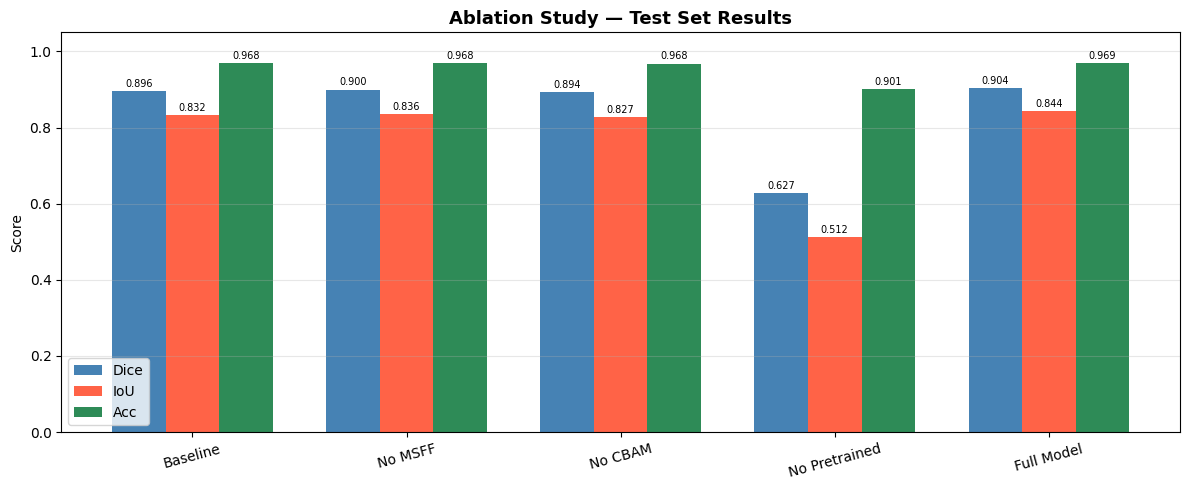

Saved: /content/outputs/ablation_chart.png


In [13]:
names  = list(ablation_results.keys())
dices  = [ablation_results[n]["dice"] for n in names]
ious   = [ablation_results[n]["iou"]  for n in names]
accs   = [ablation_results[n]["acc"]  for n in names]

x = np.arange(len(names)); w = 0.25
fig, ax = plt.subplots(figsize=(12, 5))
b1 = ax.bar(x - w, dices, w, label="Dice",  color="steelblue")
b2 = ax.bar(x,     ious,  w, label="IoU",   color="tomato")
b3 = ax.bar(x + w, accs,  w, label="Acc",   color="seagreen")
ax.set_xticks(x); ax.set_xticklabels(names, rotation=15)
ax.set_ylim(0, 1.05); ax.set_ylabel("Score")
ax.set_title("Ablation Study — Test Set Results", fontweight="bold", fontsize=13)
ax.legend(); ax.grid(axis="y", alpha=0.3)
for bars in [b1, b2, b3]:
    for bar in bars:
        ax.annotate("{:.3f}".format(bar.get_height()),
                    xy=(bar.get_x() + bar.get_width()/2, bar.get_height()),
                    xytext=(0, 3), textcoords="offset points", ha="center", fontsize=7)
plt.tight_layout()
abl_fig = os.path.join(CFG["OUTPUT_DIR"], "ablation_chart.png")
plt.savefig(abl_fig, dpi=150, bbox_inches="tight"); plt.show()
print("Saved:", abl_fig)


## Step 11: Qualitative Results + Grad-CAM

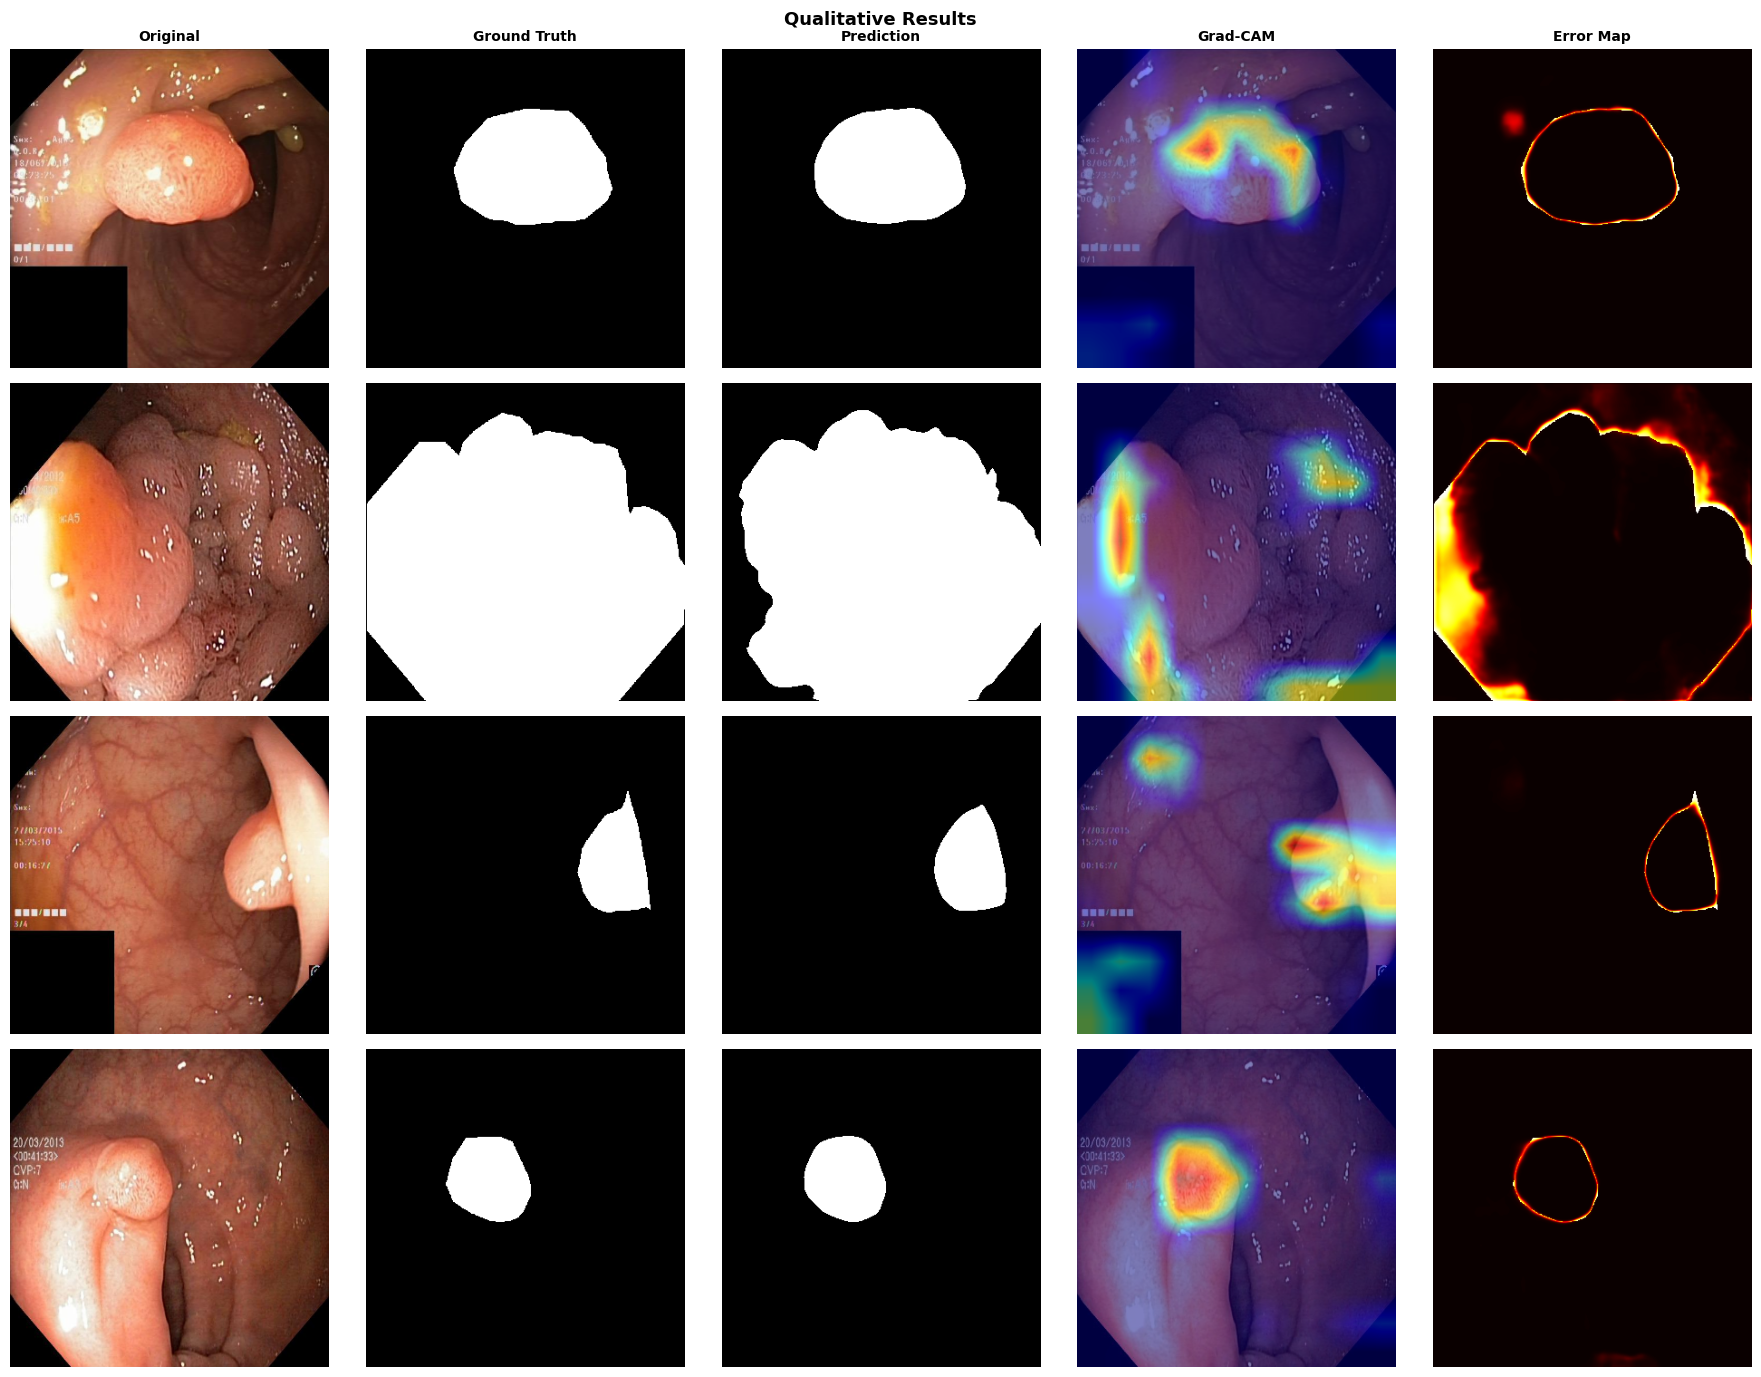

Saved: /content/outputs/qualitative_results.png


In [14]:
class GradCAM:
    def __init__(self, model, layer):
        self.model=model; self._f=None; self._g=None
        layer.register_forward_hook(lambda _,__,o: setattr(self,"_f",o.detach()))
        layer.register_full_backward_hook(lambda _,__,g: setattr(self,"_g",g[0].detach()))
    def generate(self, x):
        self.model.eval(); x=x.clone().requires_grad_(True)
        self.model(x).mean().backward()
        w=self._g.mean((2,3),keepdim=True)
        cam=F.relu((w*self._f).sum(1,keepdim=True)).squeeze().cpu().numpy()
        return (cam-cam.min())/(cam.max()-cam.min()+1e-8)

gcam=GradCAM(model, model.enc4[-1].conv3)
model.eval()
imgs_v,msks_v=next(iter(test_loader))
imgs_v=imgs_v[:4].to(DEVICE); msks_v=msks_v[:4]
with torch.no_grad(): preds_v=model(imgs_v).cpu()

fig,axes=plt.subplots(4,5,figsize=(18,14))
for j,t in enumerate(["Original","Ground Truth","Prediction","Grad-CAM","Error Map"]):
    axes[0,j].set_title(t,fontweight="bold",fontsize=10)

for i in range(4):
    orig=np.clip(imgs_v[i].cpu().permute(1,2,0).numpy()*STD+MEAN,0,1)
    orig_u8=(orig*255).astype(np.uint8)
    with torch.enable_grad(): cam=gcam.generate(imgs_v[i:i+1])
    cam=cv2.resize(cam,(CFG["IMG_SIZE"],CFG["IMG_SIZE"]))
    hm=cv2.applyColorMap((cam*255).astype(np.uint8),cv2.COLORMAP_JET)
    hm=cv2.cvtColor(hm,cv2.COLOR_BGR2RGB)
    cam_ov=np.clip(0.5*hm+0.5*orig_u8,0,255).astype(np.uint8)
    pred_np=preds_v[i,0].numpy(); gt_np=msks_v[i,0].numpy()
    axes[i,0].imshow(orig); axes[i,1].imshow(gt_np,cmap="gray")
    axes[i,2].imshow(pred_np>0.5,cmap="gray"); axes[i,3].imshow(cam_ov)
    axes[i,4].imshow(np.abs(pred_np-gt_np),cmap="hot",vmin=0,vmax=1)
    for j in range(5): axes[i,j].axis("off")

plt.suptitle("Qualitative Results",fontsize=13,fontweight="bold"); plt.tight_layout()
out_q=os.path.join(CFG["OUTPUT_DIR"],"qualitative_results.png")
plt.savefig(out_q,dpi=150,bbox_inches="tight"); plt.show(); print("Saved:",out_q)


## Step 12: Single-Image Inference
Pass an image path (from Drive or local upload) → get prediction mask + overlay.

Saved prediction: /content/outputs/pred_cju5jz5fff8c50871hbe6108f.jpg


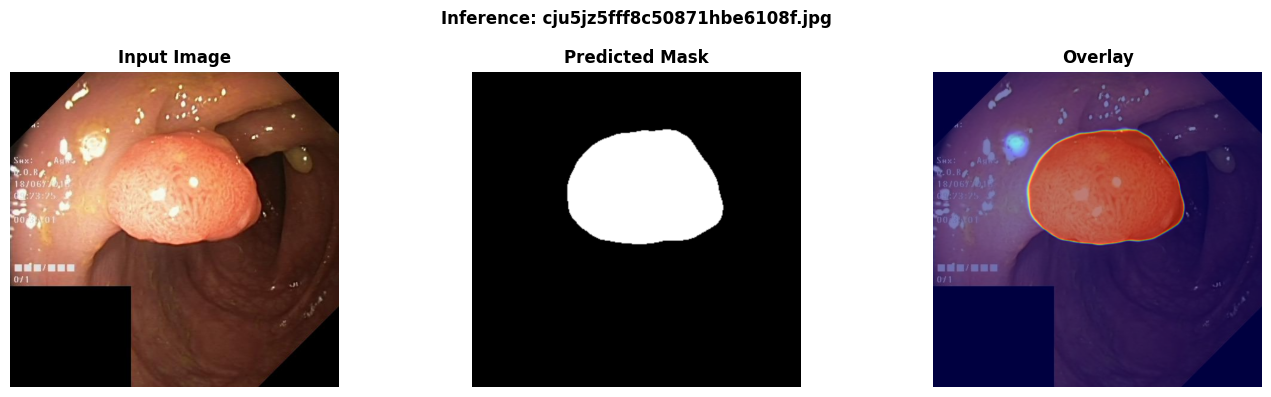

(array([[1.0625412e-05, 6.9276439e-06, 2.4678272e-06, ..., 8.5065392e-04,
         9.6867868e-04, 1.0577389e-03],
        [6.2882273e-06, 4.4586991e-06, 2.2301360e-06, ..., 7.2006573e-04,
         7.7982066e-04, 8.2189857e-04],
        [1.7510126e-06, 1.8413705e-06, 1.9082893e-06, ..., 5.5747468e-04,
         5.5926270e-04, 5.5543805e-04],
        ...,
        [1.0823563e-03, 1.1545339e-03, 1.2003310e-03, ..., 1.8795021e-03,
         3.9392221e-03, 5.5303052e-03],
        [1.2152436e-03, 1.2456800e-03, 1.2439683e-03, ..., 2.6446411e-03,
         6.3714157e-03, 9.3040215e-03],
        [1.2759889e-03, 1.2629417e-03, 1.2161764e-03, ..., 3.3724594e-03,
         8.7159732e-03, 1.2950812e-02]], dtype=float32),
 array([[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]], dtype=uint8))

In [15]:
def predict_image(img_path, model, threshold=0.5, save_dir=None):
    """
    Run segmentation on a single image.
    Args:
        img_path : str  – path to image file (jpg/png)
        model    : trained PolypSegNet
        threshold: float – binarization threshold (default 0.5)
        save_dir : str or None – if given, saves output PNG here
    Returns:
        pred_mask (H,W) float32  [0,1]
        pred_bin  (H,W) uint8 binary mask
    """
    tfm = get_val_transforms(CFG["IMG_SIZE"])
    img_orig = np.array(Image.open(img_path).convert("RGB"))
    inp = tfm(image=img_orig)["image"].unsqueeze(0).to(DEVICE)
    model.eval()
    with torch.no_grad():
        pred = model(inp)[0, 0].cpu().numpy()          # (H,W) 0-1
    pred_bin = (pred > threshold).astype(np.uint8) * 255

    # Resize back to original image size for display
    oh, ow = img_orig.shape[:2]
    pred_display = cv2.resize(pred,     (ow, oh))
    pred_bin_disp = cv2.resize(pred_bin, (ow, oh))

    # Overlay
    hm = cv2.applyColorMap((pred_display * 255).astype(np.uint8), cv2.COLORMAP_JET)
    hm = cv2.cvtColor(hm, cv2.COLOR_BGR2RGB)
    overlay = np.clip(0.5 * hm + 0.5 * img_orig, 0, 255).astype(np.uint8)

    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    axes[0].imshow(img_orig);       axes[0].set_title("Input Image",    fontweight="bold")
    axes[1].imshow(pred_bin_disp, cmap="gray"); axes[1].set_title("Predicted Mask", fontweight="bold")
    axes[2].imshow(overlay);        axes[2].set_title("Overlay",        fontweight="bold")
    for ax in axes: ax.axis("off")
    plt.suptitle("Inference: {}".format(os.path.basename(img_path)), fontweight="bold")
    plt.tight_layout()
    if save_dir:
        os.makedirs(save_dir, exist_ok=True)
        out = os.path.join(save_dir, "pred_" + os.path.basename(img_path))
        plt.savefig(out, dpi=150, bbox_inches="tight")
        print("Saved prediction:", out)
    plt.show()
    return pred_display, pred_bin_disp

# ── USAGE ──────────────────────────────────────────────────────
# Change this path to any image you want to test:
# IMG_PATH = "/content/drive/MyDrive/my_polyp_image.jpg"
# predict_image(IMG_PATH, model, threshold=0.5, save_dir=CFG["OUTPUT_DIR"])

# Example with a random test image:
sample_img = test_loader.dataset.imgs[0]
predict_image(sample_img, model, threshold=0.5, save_dir=CFG["OUTPUT_DIR"])


## Step 13: Download All Results

In [16]:
from google.colab import files
print("Downloading results...")
download_files = [
    "best_model.pth",
    "training_curves.png",
    "training_history.csv",
    "qualitative_results.png",
    "test_results.csv",
    "ablation_results.csv",
    "ablation_chart.png"
]
for fname in download_files:
    p = os.path.join(CFG["OUTPUT_DIR"], fname)
    if os.path.exists(p): files.download(p); print("  Downloaded:", fname)
    else: print("  Not found :", fname)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

  Downloaded: best_model.pth


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

  Downloaded: training_curves.png


... (11 outputs left out)

  Downloaded: ablation_results.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

  Downloaded: ablation_chart.png
